<hr>

**<h1> CS437/CS5317/EE414/EE513 Deep Learning |  PA4</h1>**

<hr>

# **Submission Guidelines**

- Please rename the file to `<RollNumber>_PA4_2`.
- Please also submit a **.py** file of every Notebook. You can do this by exporting your **ipynb** to a Python script.
- Please submit a zipped folder of both your Jupyter Notebooks and Python script files.

In [1]:
Name = "Sameer Rahil"
Roll_Number = 27100162

## Setup — Imports & Device

In [2]:
import math
import time
import collections
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)


Device: cuda


---
## Part A — Modifying the Attention Mechanism

CIFAR-10 image classification using a small ViT.  
**Dataset:** 20,000-sample training subset, full 10,000 validation set.  
**Training config:** 15 epochs, Adam lr=3e-4, CosineAnnealingLR, CrossEntropyLoss, grad clip=1.0.


### Baseline: Scaled Dot-Product Attention
Reference implementation. **Do not modify.**

In [3]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Args
        Q, K : (B, H, N, d_k)
        V    : (B, H, N, d_v)
        mask : optional boolean mask (True = ignore)
    Returns
        out  : (B, H, N, d_v)
        attn : (B, H, N, N)
    """
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(mask, float('-inf'))
    attn = F.softmax(scores, dim=-1)
    return torch.matmul(attn, V), attn


### Shared Transformer Building Blocks
`MultiHeadAttention` and `TransformerBlock` — provided. Do not modify.

In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, attention_fn=None):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.Wq = nn.Linear(d_model, d_model, bias=False)
        self.Wk = nn.Linear(d_model, d_model, bias=False)
        self.Wv = nn.Linear(d_model, d_model, bias=False)
        self.Wo = nn.Linear(d_model, d_model, bias=False)
        self.attention_fn = attention_fn or scaled_dot_product_attention

    def forward(self, x):
        B, N, D = x.shape
        def split(t):
            return t.view(B, N, self.n_heads, self.d_k).transpose(1, 2)
        Q = split(self.Wq(x))
        K = split(self.Wk(x))
        V = split(self.Wv(x))
        out, attn_w = self.attention_fn(Q, K, V)
        out = out.transpose(1, 2).contiguous().view(B, N, D)
        return self.Wo(out), attn_w


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, ff_dim, attention_fn=None):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads, attention_fn)
        self.ff   = nn.Sequential(
            nn.Linear(d_model, ff_dim), nn.ReLU(),
            nn.Linear(ff_dim, d_model)
        )
        self.ln1 = nn.LayerNorm(d_model)
        self.ln2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attn_out, _ = self.attn(self.ln1(x))
        x = x + attn_out
        x = x + self.ff(self.ln2(x))
        return x


### Dataset — CIFAR-10 (Part A)

In [5]:
import torchvision
import torchvision.transforms as T

IMG_SIZE   = 32
PATCH_SIZE = 4          # (32/4)^2 = 64 tokens per image
BATCH_A    = 128

transform_a = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465),
                (0.2470, 0.2435, 0.2616)),
])
transform_val = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465),
                (0.2470, 0.2435, 0.2616)),
])

cifar_train = torchvision.datasets.CIFAR10(root='./data', train=True,
                                            download=True, transform=transform_a)
cifar_val   = torchvision.datasets.CIFAR10(root='./data', train=False,
                                            download=True, transform=transform_val)

# 20k subset for Part A experiments
cifar_train_sub = torch.utils.data.Subset(cifar_train, range(20_000))

loader_train_a = torch.utils.data.DataLoader(cifar_train_sub, batch_size=BATCH_A,
                                              shuffle=True,  num_workers=2, pin_memory=True)
loader_val_a   = torch.utils.data.DataLoader(cifar_val,      batch_size=256,
                                              shuffle=False, num_workers=2, pin_memory=True)
CLASSES = cifar_train.classes
print(f"Train subset: {len(cifar_train_sub)}  |  Val: {len(cifar_val)}")


100%|██████████| 170M/170M [00:05<00:00, 29.0MB/s]


Train subset: 20000  |  Val: 10000


### Model — ViT Classifier for Part A
Provided. Uses `LinearPatchEmbeddingA` and accepts an `attention_fn` argument.

In [6]:
class LinearPatchEmbeddingA(nn.Module):
    def __init__(self, img_size, patch_size, in_channels, d_model):
        super().__init__()
        self.patch_size = patch_size
        self.n_patches  = (img_size // patch_size) ** 2
        self.proj = nn.Linear(patch_size * patch_size * in_channels, d_model)

    def forward(self, x):
        B, C, H, W = x.shape; P = self.patch_size
        x = x.unfold(2, P, P).unfold(3, P, P)
        x = x.contiguous().view(B, C, -1, P, P)
        x = x.permute(0, 2, 1, 3, 4).contiguous().view(B, self.n_patches, -1)
        return self.proj(x)


class ViTClassifierA(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_channels=3,
                 d_model=64, n_layers=2, n_heads=4, num_classes=10,
                 attention_fn=None):
        super().__init__()
        self.embedding = LinearPatchEmbeddingA(img_size, patch_size, in_channels, d_model)
        n_patches = self.embedding.n_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos_emb   = nn.Parameter(torch.randn(1, n_patches + 1, d_model) * 0.02)
        self.blocks    = nn.ModuleList([
            TransformerBlock(d_model, n_heads, d_model * 2, attention_fn)
            for _ in range(n_layers)])
        self.ln   = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_classes)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        B = x.size(0)
        tokens = self.embedding(x)
        cls    = self.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos_emb
        for blk in self.blocks:
            tokens = blk(tokens)
        return self.head(self.ln(tokens[:, 0]))


### Training & Evaluation Helpers (Part A)
Provided. Do not modify.

In [7]:
def train_epoch_a(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, n = 0., 0, 0
    grad_norms = []
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, labels)
        loss.backward()
        gnorm = sum(p.grad.detach().norm().item()**2
                    for p in model.parameters() if p.grad is not None) ** 0.5
        grad_norms.append(gnorm)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        n          += imgs.size(0)
    return total_loss / n, correct / n, sum(grad_norms) / len(grad_norms)


@torch.no_grad()
def evaluate_a(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0., 0, 0
    class_correct = torch.zeros(10)
    class_total   = torch.zeros(10)
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        logits = model(imgs)
        total_loss += criterion(logits, labels).item() * imgs.size(0)
        preds   = logits.argmax(1)
        correct += (preds == labels).sum().item()
        n       += imgs.size(0)
        for c in range(10):
            mask = labels == c
            class_correct[c] += (preds[mask] == c).sum().item()
            class_total[c]   += mask.sum().item()
    per_class_acc = (class_correct / class_total.clamp(min=1)).numpy()
    return total_loss / n, correct / n, per_class_acc


def attn_entropy(attn_w):
    """Mean Shannon entropy of attention distributions. attn_w: (B,H,N,N)"""
    eps = 1e-9
    return -(attn_w * (attn_w + eps).log()).sum(-1).mean().item()


@torch.no_grad()
def measure_entropy(model, loader, attn_fn, n_batches=5):
    """Average CLS-token attention entropy over n_batches mini-batches."""""
    model.eval()
    entropies = []
    for i, (imgs, _) in enumerate(loader):
        if i >= n_batches: break
        imgs = imgs.to(DEVICE)
        B    = imgs.size(0)
        tokens = model.embedding(imgs)
        cls    = model.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + model.pos_emb
        x_ln = model.blocks[0].ln1(tokens)
        d_k  = model.blocks[0].attn.d_k
        n_h  = model.blocks[0].attn.n_heads
        N    = x_ln.size(1)
        def split(t): return t.view(B, N, n_h, d_k).transpose(1, 2)
        Q = split(model.blocks[0].attn.Wq(x_ln))
        K = split(model.blocks[0].attn.Wk(x_ln))
        V = split(model.blocks[0].attn.Wv(x_ln))
        _, aw = attn_fn(Q, K, V)
        entropies.append(attn_entropy(aw))
    return sum(entropies) / len(entropies)


---
### Task 1 — Top-k Sparse Attention

**[1.1] Your implementation below.**

For each query, compute standard scaled scores, retain only the **k** highest-scoring keys (mask the rest to `-inf`), then apply softmax.  
Signature must match `scaled_dot_product_attention` plus the integer argument `k`.  
Shape: inputs are `(B, H, N, d_k)`.


In [8]:
def topk_attention(Q, K, V, k):
    """
    Args
        Q, K : (B, H, N, d_k)
        V    : (B, H, N, d_v)
        k    : number of keys each query attends to
    Returns
        out  : (B, H, N, d_v)
        attn : (B, H, N, N)
    """
    # TODO: implement top-k sparse attention
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)
    N = scores.size(-1)
    if k >= N:
        attn = F.softmax(scores, dim=-1)
        return torch.matmul(attn, V), attn
    kth = torch.topk(scores, k, dim=-1).values[..., -1:]
    scores = scores.masked_fill(scores < kth, float('-inf'))
    attn = F.softmax(scores, dim=-1)
    return torch.matmul(attn, V), attn

**[1.2] Sanity check**

In [9]:
B, H, N, d_k = 2, 4, 16, 32
Q_ = torch.randn(B, H, N, d_k)
K_ = torch.randn(B, H, N, d_k)
V_ = torch.randn(B, H, N, d_k)

out_full, _ = scaled_dot_product_attention(Q_, K_, V_)
out_topk, _ = topk_attention(Q_, K_, V_, k=N)
assert torch.allclose(out_full, out_topk, atol=1e-5), "Outputs differ when k == N"
print('Sanity check passed.')


Sanity check passed.


**[1.3] Experiment A1 — Top-k sweep.**

Run for k ∈ {4, 16, 32, full}. Training config is set below. Do not change the hyperparameters.


In [10]:
# Training configuration — do not change
EPOCHS_A   = 15
LR_A       = 3e-4
CRIT_A     = nn.CrossEntropyLoss()
K_VALS     = [4, 16, 32, None]   # None = full attention (N=65)
N_PATCHES  = (IMG_SIZE // PATCH_SIZE) ** 2   # 64
N_FULL     = N_PATCHES + 1                   # +1 for CLS

def run_topk_experiment(k_values=K_VALS, epochs=EPOCHS_A):
    results = {}
    for k in k_values:
        torch.manual_seed(42)
        label   = 'full' if k is None else str(k)
        attn_fn = (scaled_dot_product_attention if k is None
                   else lambda Q, K, V, _k=k: topk_attention(Q, K, V, k=_k))
        model  = ViTClassifierA(attention_fn=attn_fn).to(DEVICE)
        opt    = torch.optim.Adam(model.parameters(), lr=LR_A)
        sched  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        r = collections.defaultdict(list)
        for ep in range(1, epochs + 1):
            t0 = time.perf_counter()
            tr_loss, tr_acc, gnorm = train_epoch_a(model, loader_train_a, opt, CRIT_A)
            val_loss, val_acc, per_cls = evaluate_a(model, loader_val_a, CRIT_A)
            ent = measure_entropy(model, loader_val_a, attn_fn)
            sched.step()
            elapsed = time.perf_counter() - t0
            r['tr_loss'].append(tr_loss);  r['val_loss'].append(val_loss)
            r['tr_acc'].append(tr_acc);    r['val_acc'].append(val_acc)
            r['gnorm'].append(gnorm);      r['entropy'].append(ent)
            r['epoch_time'].append(elapsed)
            r['per_cls'].append(per_cls)
            print(f"  k={label:>4s} ep {ep:02d}/{epochs} "
                  f"tr_loss={tr_loss:.4f} val_acc={val_acc:.3f} "
                  f"entropy={ent:.3f} gnorm={gnorm:.3f}")
        results[label] = dict(r)
    return results

topk_res = run_topk_experiment()


  k=   4 ep 01/15 tr_loss=1.9852 val_acc=0.323 entropy=1.379 gnorm=1.910
  k=   4 ep 02/15 tr_loss=1.8154 val_acc=0.363 entropy=1.377 gnorm=2.520
  k=   4 ep 03/15 tr_loss=1.7183 val_acc=0.394 entropy=1.378 gnorm=3.245
  k=   4 ep 04/15 tr_loss=1.6540 val_acc=0.405 entropy=1.378 gnorm=3.643
  k=   4 ep 05/15 tr_loss=1.6041 val_acc=0.425 entropy=1.378 gnorm=4.017
  k=   4 ep 06/15 tr_loss=1.5550 val_acc=0.441 entropy=1.378 gnorm=4.261
  k=   4 ep 07/15 tr_loss=1.5238 val_acc=0.460 entropy=1.378 gnorm=4.479
  k=   4 ep 08/15 tr_loss=1.4922 val_acc=0.471 entropy=1.377 gnorm=4.415
  k=   4 ep 09/15 tr_loss=1.4763 val_acc=0.467 entropy=1.378 gnorm=4.690
  k=   4 ep 10/15 tr_loss=1.4530 val_acc=0.476 entropy=1.377 gnorm=4.622
  k=   4 ep 11/15 tr_loss=1.4350 val_acc=0.487 entropy=1.376 gnorm=4.946
  k=   4 ep 12/15 tr_loss=1.4238 val_acc=0.490 entropy=1.376 gnorm=4.767
  k=   4 ep 13/15 tr_loss=1.4185 val_acc=0.493 entropy=1.376 gnorm=4.818
  k=   4 ep 14/15 tr_loss=1.4174 val_acc=0.496 entr

**[1.3 cont.] Visualisation A1 — 6-panel figure.**

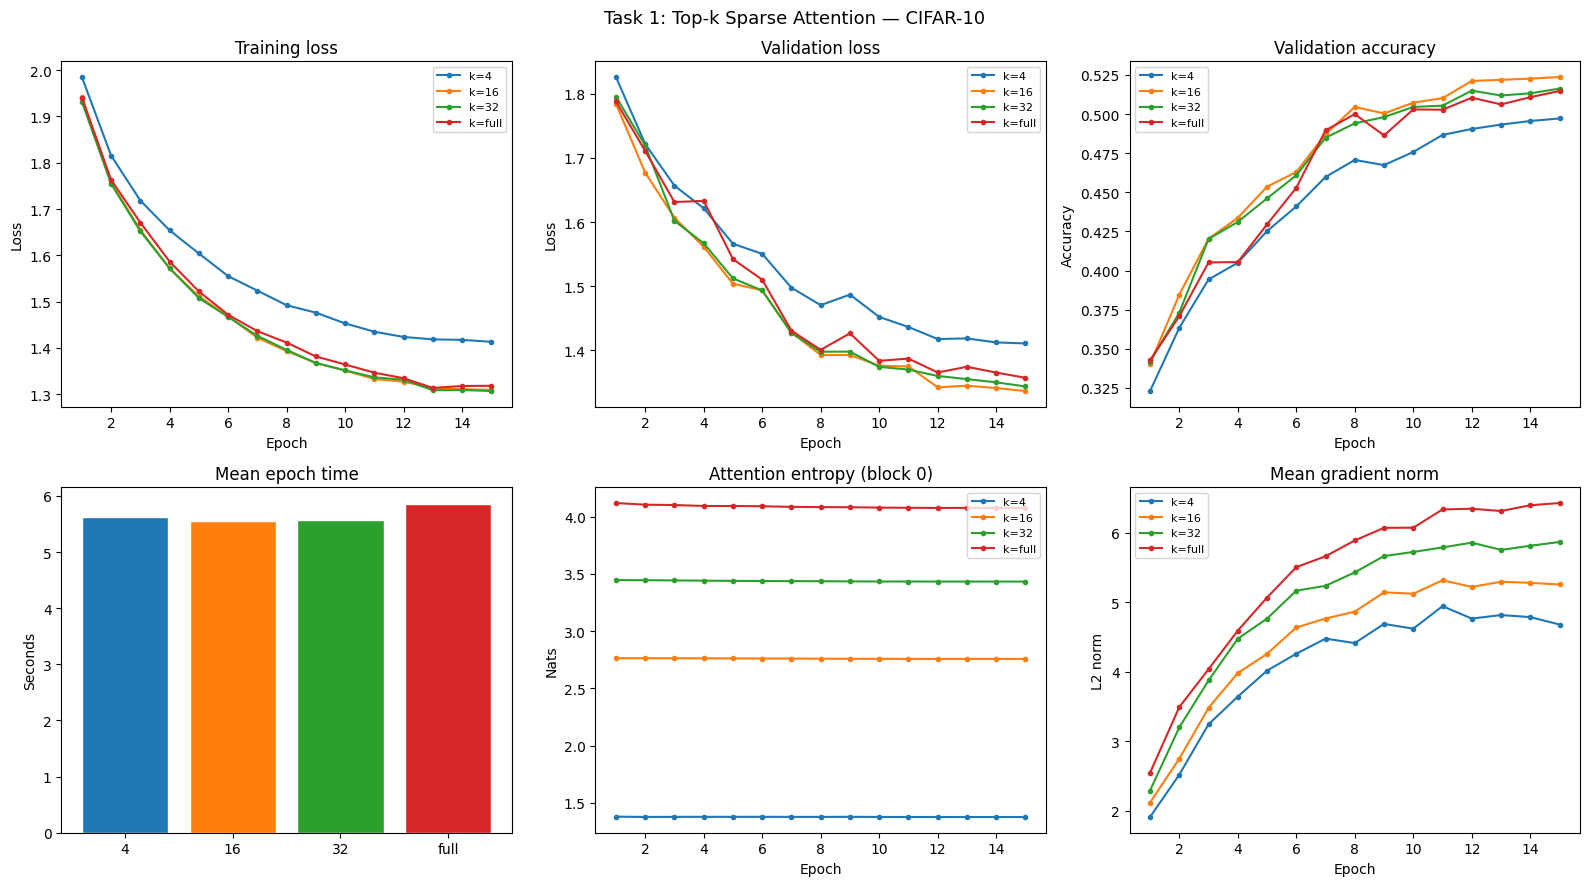

In [11]:
EPOCHS_A = len(list(topk_res.values())[0]['tr_loss'])
epochs_ax = range(1, EPOCHS_A + 1)
colors = plt.cm.tab10.colors

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
ax_trloss, ax_valloss, ax_valacc, ax_time, ax_ent, ax_gnorm = axes.flatten()

for i, (label, res) in enumerate(topk_res.items()):
    c = colors[i]
    kw = dict(color=c, marker='o', markersize=3)
    ax_trloss.plot(epochs_ax, res['tr_loss'],   label=f'k={label}', **kw)
    ax_valloss.plot(epochs_ax, res['val_loss'],  label=f'k={label}', **kw)
    ax_valacc.plot(epochs_ax, res['val_acc'],   label=f'k={label}', **kw)
    ax_ent.plot(epochs_ax,    res['entropy'],   label=f'k={label}', **kw)
    ax_gnorm.plot(epochs_ax,  res['gnorm'],     label=f'k={label}', **kw)

labels_plot = list(topk_res.keys())
times = [np.mean(topk_res[l]['epoch_time'][-3:]) for l in labels_plot]
ax_time.bar(labels_plot, times, color=[colors[i] for i in range(len(labels_plot))], edgecolor='white')

for ax, title, ylabel in [
    (ax_trloss, 'Training loss',               'Loss'),
    (ax_valloss, 'Validation loss',             'Loss'),
    (ax_valacc,  'Validation accuracy',         'Accuracy'),
    (ax_time,    'Mean epoch time',             'Seconds'),
    (ax_ent,     'Attention entropy (block 0)', 'Nats'),
    (ax_gnorm,   'Mean gradient norm',          'L2 norm'),
]:
    ax.set_title(title); ax.set_ylabel(ylabel)
    if ax != ax_time:
        ax.set_xlabel('Epoch'); ax.legend(fontsize=8)

plt.suptitle('Task 1: Top-k Sparse Attention — CIFAR-10', fontsize=13)
plt.tight_layout()
plt.show()


**[1.3 cont.] Visualisation A1b — Per-class accuracy heatmap (final epoch).**

/tmp/ipykernel_3200/4154662898.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=8)
/tmp/ipykernel_3200/4154662898.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=8)
/tmp/ipykernel_3200/4154662898.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=8)
/tmp/ipykernel_3200/4154662898.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=8)


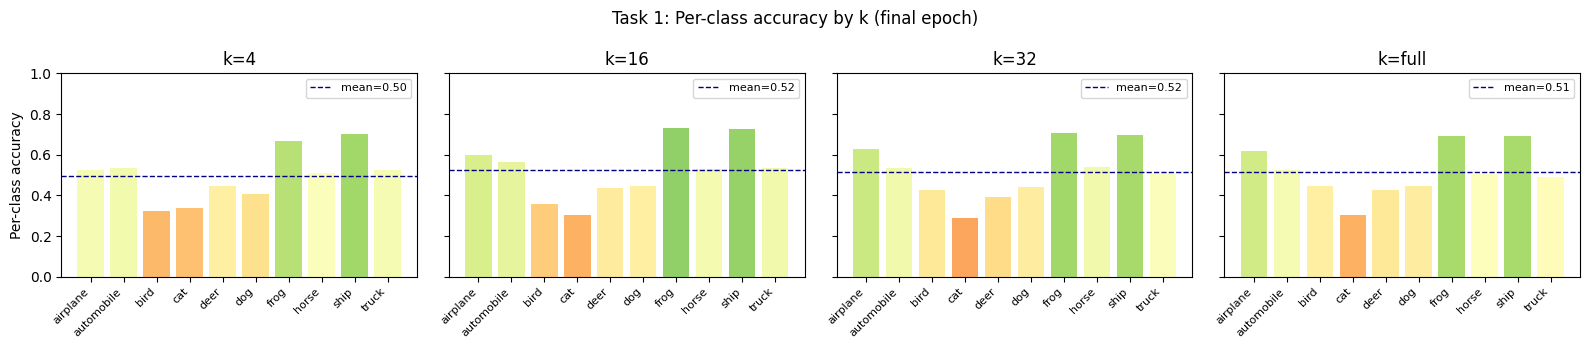

In [12]:
fig, axes = plt.subplots(1, len(topk_res), figsize=(4 * len(topk_res), 3.5), sharey=True)
if len(topk_res) == 1: axes = [axes]

for ax, (label, res) in zip(axes, topk_res.items()):
    per_cls = res['per_cls'][-1]
    ax.bar(CLASSES, per_cls, color=plt.cm.RdYlGn(per_cls))
    ax.set_title(f'k={label}')
    ax.set_ylim(0, 1)
    ax.set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=8)
    ax.axhline(per_cls.mean(), linestyle='--', color='navy', linewidth=1,
               label=f'mean={per_cls.mean():.2f}')
    ax.legend(fontsize=8)

axes[0].set_ylabel('Per-class accuracy')
plt.suptitle('Task 1: Per-class accuracy by k (final epoch)', fontsize=12)
plt.tight_layout()
plt.show()


**[1.4] Analysis — Task 1**

*Write your analysis here. Address:*
- *How does validation accuracy vary with k? Is the relationship monotonic?*
- *What does attention entropy tell you about sparsity?*
- *Comment on gradient norm trends across k.*
- *Which k would you choose in practice and why?*


Answer: Validation accuracy improves substantially as k increases from 4 to 16, but the relationship is not strictly monotonic across the whole sweep. The final validation accuracies are about 0.497 for k = 4, 0.524 for k = 16, 0.516 for k = 32, and 0.515 for full attention. This suggests that allowing each query to attend to more than 4 keys is clearly beneficial, but after a certain point the extra flexibility does not continue to help and may even slightly hurt generalisation. A moderate amount of sparsity appears to work best here because it keeps the model focused on the most relevant patch interactions while still preserving enough context.

The attention entropy results show a very clear relationship between sparsity and the shape of the attention distribution. Smaller k produces lower entropy, meaning attention is more concentrated and selective, while larger k produces higher entropy because probability mass is spread across more keys. In these results, entropy is around 1.38 for k = 4, 2.76 for k = 16, 3.43 for k = 32, and 4.08 for full attention.tis is exactly what we would expect, since top k maskng directly limits how many positions can receive meaningful attention. The nearly flat entropy curves across epochs also make sense because the sparsity pattern imposed by k domnates the overall support size of the distribution

The gradiennt norm trends also look meaningful. As k increases, the mean gradient norm becomes larger, with k = 4 staying lowest and full attention staying highest by the end of training. This suggests that denser attention creates a more complex optimisation landscape with stronger and more variable updates, while sparse attention regularises the model and keeps updates more controlled. Very small k may over constrain the model and reduce representational power, but very large k seems to incrrease optimization complexity without giving a clear accuracy benefit. So the gradient results support the idea that a moderate sparsity level provides a good balance between stability and expressiveness

In practice, I would choose k = 16. It gives the best final validation accuracy, has lower epoch time than full attention, and achieves a good balance between selectivity and access to broader context. k = 4 is too restrictive and loses useful information, while k = 32 and full attention are slightly more expensive and do not outperform k = 16. So k = 16 appears to be the most effective chioice for this setup

---
### Task 2 — Temperature-Scaled Attention

**[2.1] Fixed-temperature implementation.**

Replace the standard $1/\sqrt{d_k}$ denominator with $1/(\tau \sqrt{d_k})$.  
Confirm that `tau=1.0` recovers the baseline exactly.


In [13]:
def temperature_attention(Q, K, V, tau=1.0):
    """
    Scaled dot-product attention with temperature parameter tau.
    tau < 1 sharpens the distribution; tau > 1 smooths it.
    """
    # TODO: implement temperature-scaled attention
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / (tau * math.sqrt(d_k))
    attn = F.softmax(scores, dim=-1)
    return torch.matmul(attn, V), attn

**[2.2] Learnable-temperature module.**

Implement `LearnedTemperatureAttention` as an `nn.Module`.  
Store `log_tau` as a single `nn.Parameter` (init from `init_tau`); compute `tau = exp(log_tau)` in forward.  
The module must be passable as the `attention_fn` argument (signature: `forward(Q, K, V)`).


In [14]:
class LearnedTemperatureAttention(nn.Module):
    """
    Temperature attention with tau as a single learned scalar.
    Parameterise as exp(log_tau) to ensure tau > 0 always.
    """
    def __init__(self, init_tau=1.0):
        super().__init__()
        # TODO: store log_tau as an nn.Parameter
        self.log_tau = nn.Parameter(torch.log(torch.tensor(float(init_tau))))

    def forward(self, Q, K, V):
        # TODO: compute tau, then temperature attention
        tau = self.log_tau.exp()
        return temperature_attention(Q, K, V, tau=tau)

**[2.3] Experiment A2 — Temperature sweep.**

Run for τ ∈ {0.5, 1.0, 2.0, 4.0, 'learned'}. Training config is the same as Task 1 (EPOCHS_T = 15, LR_A).


In [15]:
# Training configuration — do not change
EPOCHS_T = 15

def run_temperature_experiment(tau_values, epochs=EPOCHS_T):
    results = {}
    for tau in tau_values:
        torch.manual_seed(42)
        label   = 'learned' if tau == 'learned' else f'tau={tau}'
        if tau == 'learned':
            lta     = LearnedTemperatureAttention(init_tau=1.0)
            attn_fn = lta
        else:
            attn_fn = lambda Q, K, V, t=tau: temperature_attention(Q, K, V, tau=t)
        model  = ViTClassifierA(attention_fn=attn_fn).to(DEVICE)
        opt    = torch.optim.Adam(model.parameters(), lr=LR_A)
        sched  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        r = collections.defaultdict(list)
        for ep in range(1, epochs + 1):
            tr_loss, tr_acc, gnorm = train_epoch_a(model, loader_train_a, opt, CRIT_A)
            _, val_acc, per_cls    = evaluate_a(model, loader_val_a, CRIT_A)
            ent = measure_entropy(model, loader_val_a, attn_fn)
            sched.step()
            r['tr_loss'].append(tr_loss);  r['val_acc'].append(val_acc)
            r['gnorm'].append(gnorm);      r['entropy'].append(ent)
            r['per_cls'].append(per_cls)
            if tau == 'learned':
                r['tau_val'].append(lta.log_tau.exp().item())
            print(f"  {label} ep {ep:02d}/{epochs} "
                  f"tr_loss={tr_loss:.4f} val_acc={val_acc:.3f} "
                  f"entropy={ent:.3f}")
        results[label] = dict(r)
    return results

tau_res = run_temperature_experiment([0.5, 1.0, 2.0, 4.0, 'learned'])


  tau=0.5 ep 01/15 tr_loss=1.9302 val_acc=0.347 entropy=4.019
  tau=0.5 ep 02/15 tr_loss=1.7480 val_acc=0.385 entropy=3.987
  tau=0.5 ep 03/15 tr_loss=1.6378 val_acc=0.425 entropy=3.973
  tau=0.5 ep 04/15 tr_loss=1.5577 val_acc=0.429 entropy=3.963
  tau=0.5 ep 05/15 tr_loss=1.4922 val_acc=0.449 entropy=3.952
  tau=0.5 ep 06/15 tr_loss=1.4495 val_acc=0.465 entropy=3.949
  tau=0.5 ep 07/15 tr_loss=1.4106 val_acc=0.499 entropy=3.931
  tau=0.5 ep 08/15 tr_loss=1.3860 val_acc=0.510 entropy=3.928
  tau=0.5 ep 09/15 tr_loss=1.3552 val_acc=0.498 entropy=3.921
  tau=0.5 ep 10/15 tr_loss=1.3380 val_acc=0.512 entropy=3.919
  tau=0.5 ep 11/15 tr_loss=1.3198 val_acc=0.514 entropy=3.910
  tau=0.5 ep 12/15 tr_loss=1.3105 val_acc=0.517 entropy=3.908
  tau=0.5 ep 13/15 tr_loss=1.2889 val_acc=0.518 entropy=3.908
  tau=0.5 ep 14/15 tr_loss=1.2949 val_acc=0.521 entropy=3.908
  tau=0.5 ep 15/15 tr_loss=1.2894 val_acc=0.524 entropy=3.908
  tau=1.0 ep 01/15 tr_loss=1.9407 val_acc=0.343 entropy=4.119
  tau=1.

**[2.3 cont.] Visualisation A2 — 6-panel figure.**

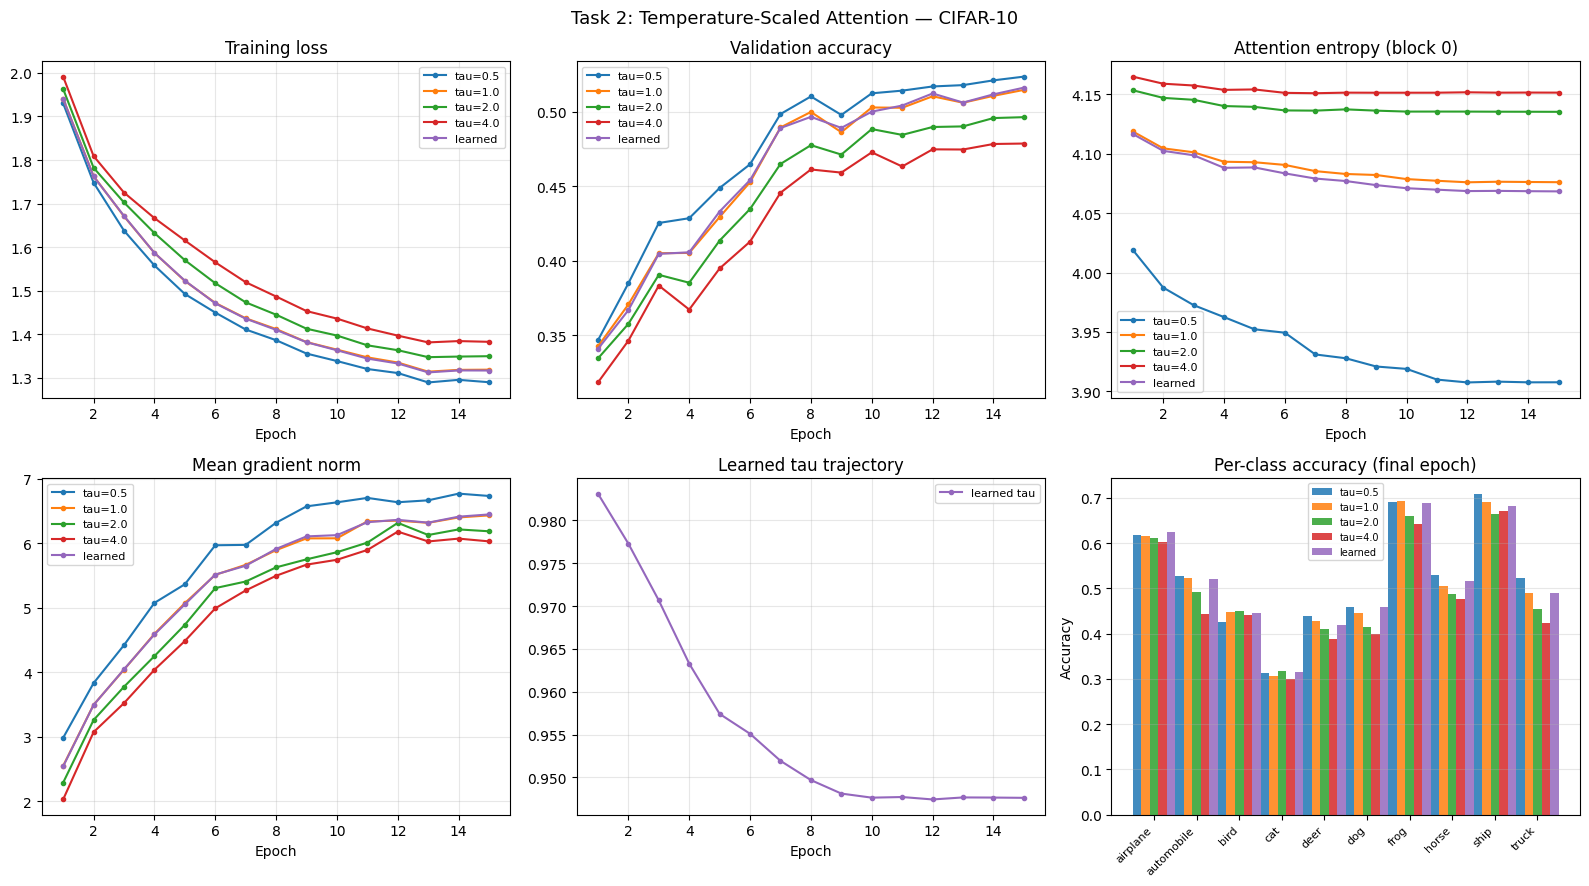

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
ax_loss, ax_acc, ax_ent, ax_gnorm, ax_tau, ax_cls = axes.flatten()
epochs_t = range(1, EPOCHS_T + 1)

for i, (label, res) in enumerate(tau_res.items()):
    c = colors[i]
    kw = dict(color=c, marker='o', markersize=3, label=label)
    ax_loss.plot(epochs_t, res['tr_loss'],  **kw)
    ax_acc.plot(epochs_t,  res['val_acc'],  **kw)
    ax_ent.plot(epochs_t,  res['entropy'],  **kw)
    ax_gnorm.plot(epochs_t, res['gnorm'],   **kw)
    if 'tau_val' in res:
        ax_tau.plot(epochs_t, res['tau_val'], color=c, marker='o',
                    markersize=3, label='learned tau')

x = np.arange(10)
width = 0.2
for i, (label, res) in enumerate(tau_res.items()):
    ax_cls.bar(x + i * width, res['per_cls'][-1],
               width=width, label=label, alpha=0.85)
ax_cls.set_xticks(x + width * 2)
ax_cls.set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=8)
ax_cls.set_ylabel('Accuracy'); ax_cls.set_title('Per-class accuracy (final epoch)')
ax_cls.legend(fontsize=7); ax_cls.grid(True, axis='y', alpha=0.3)

for ax, title in [(ax_loss, 'Training loss'),
                  (ax_acc,  'Validation accuracy'),
                  (ax_ent,  'Attention entropy (block 0)'),
                  (ax_gnorm,'Mean gradient norm'),
                  (ax_tau,  'Learned tau trajectory')]:
    ax.set_title(title); ax.set_xlabel('Epoch')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle('Task 2: Temperature-Scaled Attention — CIFAR-10', fontsize=13)
plt.tight_layout()
plt.show()


**[2.4] Analysis — Task 2**

*Write your analysis here. Address:*
- *How do sharp (τ < 1) and flat (τ > 1) attention affect accuracy?*
- *What value does the learned τ converge to? Does it align with the fixed-τ sweep?*
- *How does temperature interact with attention entropy? Provide specific numbers.*

Answer: sharp attention with toau less than 1 improves validation accuracy in this experiment, while flatter attention with tau greater than 1 hurts performance. The best result comes from tau = 0.5, which reaches about 0.524 validation accuracy by the final epoch. The baseline tau = 1.0 finishes at about 0.515,while tau = 2.0 and tau = 4.0 finish lower at about 0.496 and 0.479. This suggests that sharper attention helps the model focus more strongly on the most relevant image patches, which is useful for CIFAR-10 where local discriminative regions often matter. In contrast, larger tau makes the attention dstribution too soft, so info is averaged over many patches and the model becomes less selective

The learned temperature converges to about 0.947 to 0.948. This does align with the fixed-tau sweep in direction, because the model clearly moves below 1.0 rather than above it, which means it prefers sharper attention over flatter attention. However, it does not move all the way down to 0.5 even though tau = 0.5 gives the best final accuracy. So the learned result is only a partial match to the sweep. It agrees that some sharpening is beneficial, but it settles on a milder sharpening level, likely because that gives a safer optimization tradeoff during training

temperature has a clear inverse relationship with attention entropy.l;ower tau produces lower entropy, meaning more concentrated attention, while higher tau produces higher entropy, meaning more diffuse attention. By the final epoch, tau = 0.5 has entropy around 3.908, tau = 1.0 has about 4.076, tau = 2.0 has about 4.135, and tau = 4.0 has about 4.152. The learned model ends near 4.068, which is slightly lower than the baseline and consistent with its learned tau being just below 1. These numbers support the interpretation that sharper attention distributions are more selective and, in this experiment, more effective for classification.

One more useful interepretation is that the learned model behaves very similarly to the baseline, but with a slight bias toward sharper attention. That is why its final accuracy is close to tau = 1.0, but its entropy is a little lower and its learned tau settles just under 1..

---
### Visualisation A3 — Attention Maps on Sample CIFAR-10 Images

**[3.1]** Using the best-performing model from Task 2, extract and visualise CLS-token attention maps.  
The extraction function `get_cls_attn_map` is provided. Apply it to at least 4 validation images from different classes.


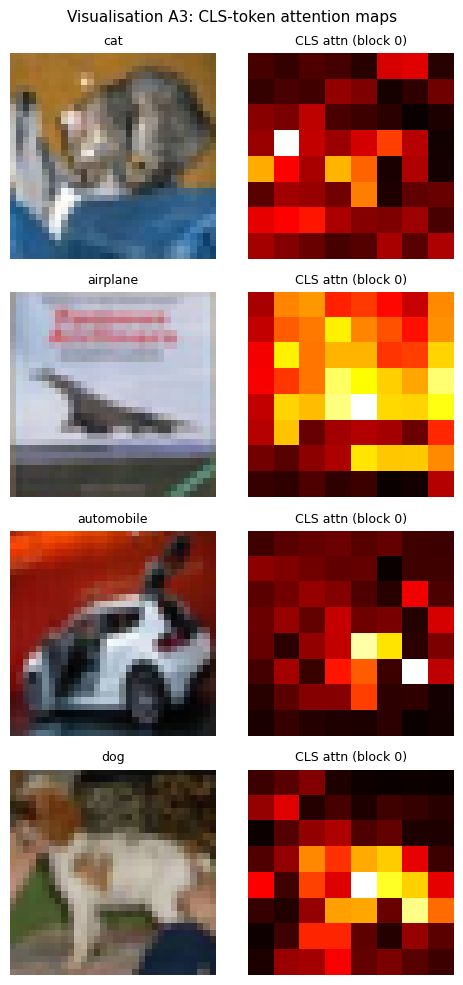

In [17]:
CIFAR_CLASSES = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]


@torch.no_grad()
def get_cls_attn_map(model, img_tensor, attn_fn):
    """
    Returns the CLS -> patch attention weights from block 0, averaged over heads.
    Args:
        img_tensor: (1, 3, H, W)
    Returns:
        (H_p, W_p) numpy array
    """
    model.eval()
    B = 1
    tokens = model.embedding(img_tensor.to(DEVICE))
    cls = model.cls_token.expand(B, -1, -1)
    tokens = torch.cat([cls, tokens], dim=1) + model.pos_emb
    x_ln = model.blocks[0].ln1(tokens)
    d_k = model.blocks[0].attn.d_k
    n_h = model.blocks[0].attn.n_heads
    N = x_ln.size(1)
    def split(t):
        return t.view(B, N, n_h, d_k).transpose(1, 2)
    Q = split(model.blocks[0].attn.Wq(x_ln))
    K = split(model.blocks[0].attn.Wk(x_ln))
    V = split(model.blocks[0].attn.Wv(x_ln))
    _, aw = attn_fn(Q, K, V)  # (1, H, N, N)
    cls_attn = aw[0, :, 0, 1:].mean(0)  # (N_patches,)
    h_p = w_p = int(cls_attn.size(0) ** 0.5)
    return cls_attn.cpu().numpy().reshape(h_p, w_p)


# Pick 4 sample images from validation set (one per class of interest)
sample_classes = [0, 1, 3, 5]  # airplane, automobile, cat, dog
sample_imgs, sample_lbls = [], []
class_seen = set()
for img, lbl in cifar_val:
    if lbl in sample_classes and lbl not in class_seen:
        sample_imgs.append(img)
        sample_lbls.append(lbl)
        class_seen.add(lbl)
    if len(class_seen) == len(sample_classes):
        break

# TODO: select your best model from Task 2 and assign to `best_model` and `best_attn_fn`
# e.g., best_model = ...   best_attn_fn = ...
best_label = max(tau_res, key=lambda k: tau_res[k]['val_acc'][-1])
torch.manual_seed(42)
if best_label == 'learned':
    lta = LearnedTemperatureAttention(init_tau=1.0)
    best_attn_fn = lta
else:
    best_tau = float(best_label.split('=')[1])
    best_attn_fn = lambda Q, K, V, t=best_tau: temperature_attention(Q, K, V, tau=t)
best_model = ViTClassifierA(attention_fn=best_attn_fn).to(DEVICE)
best_opt = torch.optim.Adam(best_model.parameters(), lr=LR_A)
best_sched = torch.optim.lr_scheduler.CosineAnnealingLR(best_opt, T_max=EPOCHS_T)
for _ in range(EPOCHS_T):
    train_epoch_a(best_model, loader_train_a, best_opt, CRIT_A)
    evaluate_a(best_model, loader_val_a, CRIT_A)
    best_sched.step()

# Visualise — original image + attention heatmap side by side
fig, axes = plt.subplots(len(sample_imgs), 2,
                         figsize=(5, 2.5 * len(sample_imgs)))

MEAN = torch.tensor([0.4914, 0.4822, 0.4465])
STD  = torch.tensor([0.2470, 0.2435, 0.2616])

for row, (img_t, lbl) in enumerate(zip(sample_imgs, sample_lbls)):
    img_vis = img_t * STD[:, None, None] + MEAN[:, None, None]
    img_vis = img_vis.permute(1, 2, 0).clamp(0, 1).numpy()

    attn_map = get_cls_attn_map(best_model,
                                img_t.unsqueeze(0),
                                best_attn_fn)

    axes[row, 0].imshow(img_vis); axes[row, 0].axis('off')
    axes[row, 0].set_title(CIFAR_CLASSES[lbl], fontsize=9)
    axes[row, 1].imshow(attn_map, cmap='hot', interpolation='nearest')
    axes[row, 1].axis('off')
    axes[row, 1].set_title('CLS attn (block 0)', fontsize=9)

plt.suptitle('Visualisation A3: CLS-token attention maps', fontsize=11)
plt.tight_layout()
plt.show()

**[3.1] Attention map analysis (2–3 sentences)**

*Is the attention spatially focused? What does this imply about what the model has learned?*

Answer: Teh attention maps are reasonably spatially focused rather than uniform. In the airplane, automobile, and dog examples, the brighter patches tend to concentrate around the object or nearby informative regions, which suggests the model haslearned to assign more importance to semantically useful parts of the image when forming the CLS representation. The maps are still somwhat coarse and spread out, which is expected because the attention is measured at patch level and from the first transformer block, so the model is learning meaningful spatial structure but not yet extremely sharp localization.


---
---
## Part B — Hybrid CNN + Vision Transformer

Full CIFAR-10 (50,000 training images). Additional augmentation: ColorJitter.  
**Training config:** 25 epochs, Adam lr=3e-4, weight_decay=1e-4, CosineAnnealingLR, CrossEntropyLoss(label_smoothing=0.1), grad clip=1.0.


### Dataset — CIFAR-10 (Part B)

In [18]:
import torchvision
import torchvision.transforms as T

IMG_SIZE   = 32
PATCH_SIZE = 4
BATCH_SIZE = 128

transform_train = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465),
                (0.2470, 0.2435, 0.2616)),
])
transform_test = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465),
                (0.2470, 0.2435, 0.2616)),
])

train_set_b = torchvision.datasets.CIFAR10(root='./data', train=True,
                                            download=True, transform=transform_train)
val_set_b   = torchvision.datasets.CIFAR10(root='./data', train=False,
                                            download=True, transform=transform_test)

train_loader = torch.utils.data.DataLoader(train_set_b, batch_size=BATCH_SIZE,
                                            shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = torch.utils.data.DataLoader(val_set_b,   batch_size=256,
                                            shuffle=False, num_workers=2, pin_memory=True)
print(f"Train: {len(train_set_b)}  |  Val: {len(val_set_b)}")


Train: 50000  |  Val: 10000


---
### Task 3 — Baseline: Vanilla ViT with Linear Patch Embedding

**[4.1] Implement `LinearPatchEmbedding`.**

Flatten each P×P patch and apply a linear projection to d_model.  
Input: `(B, C, H, W)`. Output: `(B, N, d_model)` where `N = (H/P)^2`.  
Do **not** add the CLS token or positional embedding here.


In [19]:
class LinearPatchEmbedding(nn.Module):
    def __init__(self, img_size, patch_size, in_channels, d_model):
        super().__init__()
        self.patch_size = patch_size
        self.n_patches  = (img_size // patch_size) ** 2
        # TODO: define the linear projection layer
        self.proj = nn.Linear(patch_size * patch_size * in_channels, d_model)

    def forward(self, x):
        # TODO: extract patches and project to d_model
        # Hint: use x.unfold to extract patches, then reshape and project
        B, C, H, W = x.shape
        P = self.patch_size
        x = x.unfold(2, P, P).unfold(3, P, P)
        x = x.contiguous().view(B, C, -1, P, P)
        x = x.permute(0, 2, 1, 3, 4).contiguous().view(B, self.n_patches, -1)
        return self.proj(x)

**[4.2] Implement `VanillaViT`.**

- Accept an `embedding_cls` argument (defaulting to `LinearPatchEmbedding`).
- Prepend a learnable CLS token, add learnable positional embedding.
- Pass through all Transformer blocks (full attention, no modifications from Part A).
- Apply LayerNorm and classify from the CLS output only.
- Initialise CLS token with `trunc_normal_(std=0.02)`.


In [20]:
class VanillaViT(nn.Module):
    """
    Vision Transformer with swappable patch embedding.
    Classification from the [CLS] token output.
    """
    def __init__(self, img_size=32, patch_size=4, in_channels=3,
                 d_model=128, n_layers=4, n_heads=4, num_classes=10,
                 embedding_cls=None):
        super().__init__()
        if embedding_cls is None:
            embedding_cls = LinearPatchEmbedding
        # TODO: instantiate embedding, CLS token, positional embedding, blocks, head
        self.embedding = embedding_cls(img_size, patch_size, in_channels, d_model)
        n_patches = self.embedding.n_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos_emb = nn.Parameter(torch.randn(1, n_patches + 1, d_model) * 0.02)
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, d_model * 2)
            for _ in range(n_layers)
        ])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_classes)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        # TODO: implement forward pass
        B = x.size(0)
        tokens = self.embedding(x)
        cls = self.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos_emb
        for blk in self.blocks:
            tokens = blk(tokens)
        return self.head(self.ln(tokens[:, 0]))

    def n_params(self):
        return sum(p.numel() for p in self.parameters())

**Shape sanity check**

In [21]:
D_MODEL = 128
dummy   = torch.randn(4, 3, IMG_SIZE, IMG_SIZE)

lin_emb = LinearPatchEmbedding(IMG_SIZE, PATCH_SIZE, 3, D_MODEL)
# CNNPatchEmbedding will be defined in Task 4; skip for now
assert lin_emb(dummy).shape == (4, (IMG_SIZE // PATCH_SIZE)**2, D_MODEL), "LinearPatchEmbedding shape mismatch"
print('Linear embedding shape check passed:', lin_emb(dummy).shape)


Linear embedding shape check passed: torch.Size([4, 64, 128])


---
### Task 4 — Hybrid CNN Patch Embedding Stem

**[5.1] Implement `CNNPatchEmbedding`.**

Two-layer convolutional stem:
1. `Conv2d(C_in, d//2, kernel=3, stride=1, padding=1)` → ReLU (full-resolution local features)
2. `Conv2d(d//2, d, kernel=P, stride=P)` → ReLU (downsamples to patch grid, projects to d_model)

Reshape output from `(B, d, H/P, W/P)` to `(B, N, d_model)`.  
Output shape must be **identical** to `LinearPatchEmbedding` for the same input.


In [22]:
class CNNPatchEmbedding(nn.Module):
    """
    Two-layer convolutional stem.
    Layer 1: local feature extraction at full resolution.
    Layer 2: simultaneous patch downsampling and d_model projection.
    """
    def __init__(self, img_size, patch_size, in_channels, d_model):
        super().__init__()
        self.patch_size = patch_size
        self.n_patches  = (img_size // patch_size) ** 2
        # TODO: define the two-layer conv stem
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, d_model // 2, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(d_model // 2, d_model, kernel_size=patch_size, stride=patch_size),
            nn.ReLU()
        )

    def forward(self, x):
        # TODO: apply stem, reshape to (B, N, d_model)
        x = self.stem(x)
        B, D, H, W = x.shape
        return x.flatten(2).transpose(1, 2)

**Shape assertion — both embeddings must have identical

output shape.**

In [23]:
dummy = torch.randn(4, 3, IMG_SIZE, IMG_SIZE)
lin_emb = LinearPatchEmbedding(IMG_SIZE, PATCH_SIZE, 3, D_MODEL)
cnn_emb = CNNPatchEmbedding(IMG_SIZE, PATCH_SIZE, 3, D_MODEL)

assert lin_emb(dummy).shape == cnn_emb(dummy).shape, "Shape mismatch between embeddings"
print('Embedding output shape:', cnn_emb(dummy).shape)  # expected: (4, 64, 128)


Embedding output shape: torch.Size([4, 64, 128])


### Training & Evaluation Helpers (Part B)
Provided. Do not modify.

In [24]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, n = 0., 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        n          += imgs.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0., 0, 0
    class_correct = torch.zeros(10)
    class_total   = torch.zeros(10)
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        logits = model(imgs)
        total_loss += criterion(logits, labels).item() * imgs.size(0)
        preds   = logits.argmax(1)
        correct += (preds == labels).sum().item()
        n       += imgs.size(0)
        for c in range(10):
            mask = labels == c
            class_correct[c] += (preds[mask] == c).sum().item()
            class_total[c]   += mask.sum().item()
    per_class = (class_correct / class_total.clamp(min=1)).numpy()
    return total_loss / n, correct / n, per_class


**[5.2] Training — 25 epochs, full CIFAR-10.**

Run both models. Training config is fixed below. Do not change hyperparameters.


In [25]:
# Training configuration — do not change
EPOCHS = 25
LR     = 3e-4

results = {}

for name, emb_cls in [('Vanilla ViT',   LinearPatchEmbedding),
                       ('Hybrid CNN+ViT', CNNPatchEmbedding)]:
    torch.manual_seed(42)
    model = VanillaViT(
        img_size=IMG_SIZE, patch_size=PATCH_SIZE, in_channels=3,
        d_model=D_MODEL, n_layers=4, n_heads=4, num_classes=10,
        embedding_cls=emb_cls
    ).to(DEVICE)
    print(f"{name}: {model.n_params():,} parameters")

    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    per_class_history = []
    epoch_times = []

    for epoch in range(1, EPOCHS + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc, per_cls = evaluate(model, val_loader, criterion)
        scheduler.step()
        elapsed = time.perf_counter() - t0

        train_losses.append(tr_loss); val_losses.append(val_loss)
        train_accs.append(tr_acc);   val_accs.append(val_acc)
        per_class_history.append(per_cls)
        epoch_times.append(elapsed)

        print(f"{name} | ep {epoch:02d}/{EPOCHS} "
              f"tr_loss={tr_loss:.4f} val_loss={val_loss:.4f} "
              f"tr_acc={tr_acc:.3f} val_acc={val_acc:.3f} ({elapsed:.1f}s)")

    results[name] = {
        'train_loss': train_losses, 'val_loss':   val_losses,
        'train_acc':  train_accs,   'val_acc':    val_accs,
        'per_class':  per_class_history,
        'n_params':   model.n_params(),
    }


Vanilla ViT: 544,138 parameters
Vanilla ViT | ep 01/25 tr_loss=1.8769 val_loss=1.7640 tr_acc=0.346 val_acc=0.421 (18.8s)
Vanilla ViT | ep 02/25 tr_loss=1.6370 val_loss=1.5404 tr_acc=0.468 val_acc=0.525 (18.6s)
Vanilla ViT | ep 03/25 tr_loss=1.5291 val_loss=1.4448 tr_acc=0.521 val_acc=0.561 (18.7s)
Vanilla ViT | ep 04/25 tr_loss=1.4643 val_loss=1.4144 tr_acc=0.555 val_acc=0.583 (18.8s)
Vanilla ViT | ep 05/25 tr_loss=1.4138 val_loss=1.3671 tr_acc=0.578 val_acc=0.599 (18.6s)
Vanilla ViT | ep 06/25 tr_loss=1.3674 val_loss=1.3428 tr_acc=0.601 val_acc=0.614 (18.2s)
Vanilla ViT | ep 07/25 tr_loss=1.3317 val_loss=1.2752 tr_acc=0.619 val_acc=0.647 (18.9s)
Vanilla ViT | ep 08/25 tr_loss=1.2941 val_loss=1.2501 tr_acc=0.637 val_acc=0.654 (18.7s)
Vanilla ViT | ep 09/25 tr_loss=1.2680 val_loss=1.2656 tr_acc=0.648 val_acc=0.650 (18.9s)
Vanilla ViT | ep 10/25 tr_loss=1.2407 val_loss=1.2114 tr_acc=0.662 val_acc=0.680 (18.5s)
Vanilla ViT | ep 11/25 tr_loss=1.2140 val_loss=1.2083 tr_acc=0.674 val_acc=0.6

**[5.3] Visualisation B — Loss curves, accuracy, generalisation gap.**

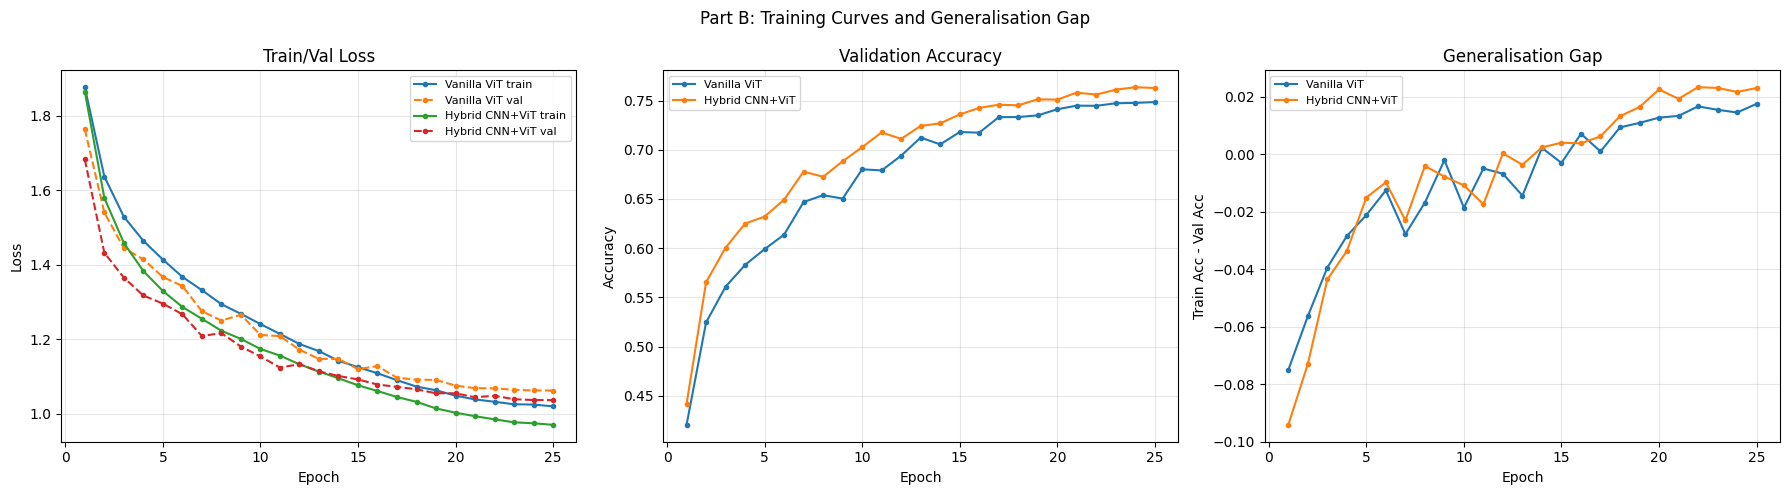

In [26]:
#TODO: plot training curves for both models (loss, accuracy, generalisation gap)
epochs_ax = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax_loss, ax_acc, ax_gap = axes

for name, res in results.items():
    ax_loss.plot(epochs_ax, res['train_loss'], marker='o', markersize=3, label=f'{name} train')
    ax_loss.plot(epochs_ax, res['val_loss'], marker='o', markersize=3, linestyle='--', label=f'{name} val')
    ax_acc.plot(epochs_ax, res['val_acc'], marker='o', markersize=3, label=name)
    gap = np.array(res['train_acc']) - np.array(res['val_acc'])
    ax_gap.plot(epochs_ax, gap, marker='o', markersize=3, label=name)

ax_loss.set_title('Train/Val Loss')
ax_loss.set_xlabel('Epoch')
ax_loss.set_ylabel('Loss')
ax_loss.legend(fontsize=8)
ax_loss.grid(True, alpha=0.3)

ax_acc.set_title('Validation Accuracy')
ax_acc.set_xlabel('Epoch')
ax_acc.set_ylabel('Accuracy')
ax_acc.legend(fontsize=8)
ax_acc.grid(True, alpha=0.3)

ax_gap.set_title('Generalisation Gap')
ax_gap.set_xlabel('Epoch')
ax_gap.set_ylabel('Train Acc - Val Acc')
ax_gap.legend(fontsize=8)
ax_gap.grid(True, alpha=0.3)

plt.suptitle('Part B: Training Curves and Generalisation Gap', fontsize=12)
plt.tight_layout()
plt.show()

**[5.3 cont.] Per-class accuracy heatmaps over training.**

/tmp/ipykernel_3200/1657736033.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


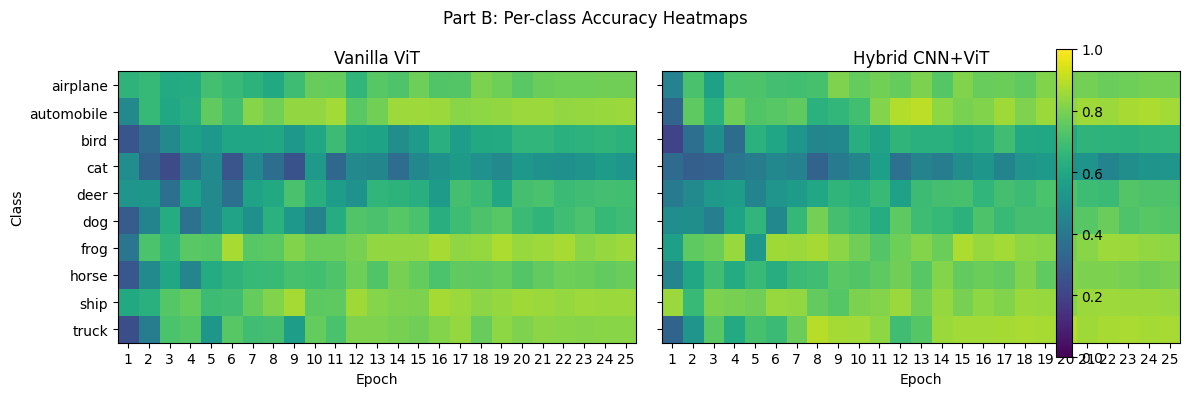

In [27]:
#TODO: plot per-class accuracy over epochs as a heatmap for both models
fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 4), sharey=True)
if len(results) == 1:
    axes = [axes]

for ax, (name, res) in zip(axes, results.items()):
    data = np.array(res['per_class']).T
    im = ax.imshow(data, aspect='auto', cmap='viridis', vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel('Epoch')
    ax.set_xticks(np.arange(EPOCHS))
    ax.set_xticklabels(np.arange(1, EPOCHS + 1))
    ax.set_yticks(np.arange(len(CLASSES)))
    ax.set_yticklabels(CLASSES)

axes[0].set_ylabel('Class')
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.04)
plt.suptitle('Part B: Per-class Accuracy Heatmaps', fontsize=12)
plt.tight_layout()
plt.show()

**[5.3 cont.] Final per-class comparison bar chart + summary table.**

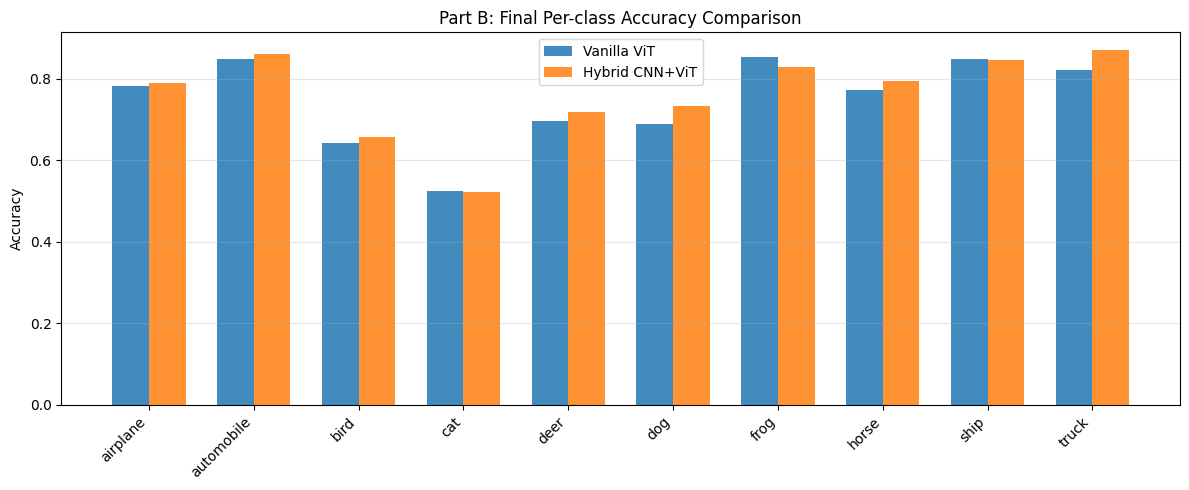

Model                    Params  Final Train Acc  Final Val Acc    Gen Gap
Vanilla ViT             544,138           0.7660         0.7484     0.0176
Hybrid CNN+ViT          670,858           0.7858         0.7627     0.0231


In [28]:
#TODO: plot bar chart of final per-class accuracy for both models side by side, and print a table of results
x = np.arange(len(CLASSES))
width = 0.35
fig, ax = plt.subplots(figsize=(12, 5))

for i, (name, res) in enumerate(results.items()):
    ax.bar(x + i * width, res['per_class'][-1], width=width, label=name, alpha=0.85)

ax.set_xticks(x + width / 2)
ax.set_xticklabels(CLASSES, rotation=45, ha='right')
ax.set_ylabel('Accuracy')
ax.set_title('Part B: Final Per-class Accuracy Comparison')
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'Model':<18} {'Params':>12} {'Final Train Acc':>16} {'Final Val Acc':>14} {'Gen Gap':>10}")
for name, res in results.items():
    final_train = res['train_acc'][-1]
    final_val = res['val_acc'][-1]
    gap = final_train - final_val
    print(f"{name:<18} {res['n_params']:>12,} {final_train:>16.4f} {final_val:>14.4f} {gap:>10.4f}")

**[5.3] Analysis — Part B**

*Write your analysis here. Address:*
- *Does the CNN stem improve overall validation accuracy? By how much?*
- *Which classes benefit most and least? Hypothesise why.*
- *Comment on the generalisation gap. Which model generalises better?*
- *Given the parameter counts, is the improvement cost-effective?*

Answer: The cnN stem does improve overall validation accuracy.The final validation accuracy increase from 0.7484 for the vanilla ViT to 0.7627 for the hybrid CNN+ViT, which is an improvement of about 0.0143 or 1.43 percentage points. The hybrid model also achieves a lower final validation loss, so the gain is consistent across both accuracy and loss rather than being a noisy one off result.

The classes that seem to benefit most from the cnn stem are deer, dog, horse, and truck, while cat changes very little and frog actually becomes slightly worse. this makes sense because the CNN stem introduces a stronger local spatial inductive bias, which is especially helpful for classes where texture, edges, and local object parts are important. For classes like cat, where performance is already relatively low and visual variation is high, the added local bias may not be enough to solve the harder ambiguity. Frog already performs very strongly in the baseline, so there may be less room for improvement there

The generalization gap stays fairly small for both models, which suggests that both architectures generalise reasosably well. By the final epoch, the Vanilla ViT has a gap of about 0.0176, while the Hybrid CNN+ViT has a slightly larger gap of about 0.0231. So strictly speaking, the Vanilla ViT generalises slightly better in terms of having the smaller train minus validation difference. However, the hybrid still achieves the better validation accuracy overall, so even with a slightly larger gap it is still the stronger model on the actual held out data.

Given the parameter counts, the improvement looks cost effective. The vanilla ViT has 544138 parameters, while the Hybrid CNN+Vit has 670858 parameters, which is an increase of about 126720 parameters. In return, it gains 1.43 percentage points in validation accuracy and improves validation loss as well. Since the runtime per epoch is also very similar in your logs, the extra cost is moderate and the performance gain appears worthwhile.

---
## Patch Size Sweep (20 pts)

**[6.1] Sweep P ∈ {2, 4, 8} using the Hybrid CNN+ViT model.**

Train for 10 epochs. All other hyperparameters identical to Part B (same LR, weight_decay, label_smoothing, scheduler).  
Record: val accuracy per epoch, mean epoch time, number of tokens N, total parameters.


In [29]:
# Training configuration — do not change
EPOCHS_SWEEP = 10

patch_sweep_results = {}

for P in [2, 4, 8]:
    torch.manual_seed(42)
    model = VanillaViT(
        img_size=IMG_SIZE, patch_size=P, in_channels=3,
        d_model=D_MODEL, n_layers=4, n_heads=4, num_classes=10,
        embedding_cls=CNNPatchEmbedding
    ).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_SWEEP)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    val_accs = []
    epoch_times = []
    final_per_class = None
    for epoch in range(1, EPOCHS_SWEEP + 1):
        t0 = time.perf_counter()
        train_one_epoch(model, train_loader, optimizer, criterion)
        _, val_acc, per_cls = evaluate(model, val_loader, criterion)
        scheduler.step()
        elapsed = time.perf_counter() - t0
        val_accs.append(val_acc)
        epoch_times.append(elapsed)
        final_per_class = per_cls
        print(f"P={P} | ep {epoch:02d}/{EPOCHS_SWEEP} val_acc={val_acc:.4f} ({elapsed:.1f}s)")
    patch_sweep_results[P] = {
        'val_acc': val_accs,
        'epoch_time': epoch_times,
        'n_tokens': (IMG_SIZE // P) ** 2,
        'n_params': model.n_params(),
        'per_class': final_per_class
    }

P=2 | ep 01/10 val_acc=0.4908 (18.7s)
P=2 | ep 02/10 val_acc=0.5389 (18.8s)
P=2 | ep 03/10 val_acc=0.5928 (19.0s)
P=2 | ep 04/10 val_acc=0.6299 (19.0s)
P=2 | ep 05/10 val_acc=0.6430 (19.5s)
P=2 | ep 06/10 val_acc=0.6639 (18.8s)
P=2 | ep 07/10 val_acc=0.6763 (19.4s)
P=2 | ep 08/10 val_acc=0.6921 (19.5s)
P=2 | ep 09/10 val_acc=0.6955 (19.3s)
P=2 | ep 10/10 val_acc=0.7044 (19.1s)
P=4 | ep 01/10 val_acc=0.4418 (19.1s)
P=4 | ep 02/10 val_acc=0.5610 (18.9s)
P=4 | ep 03/10 val_acc=0.5965 (18.8s)
P=4 | ep 04/10 val_acc=0.6227 (19.2s)
P=4 | ep 05/10 val_acc=0.6398 (19.1s)
P=4 | ep 06/10 val_acc=0.6526 (19.7s)
P=4 | ep 07/10 val_acc=0.6788 (18.7s)
P=4 | ep 08/10 val_acc=0.6871 (19.2s)
P=4 | ep 09/10 val_acc=0.6943 (19.3s)
P=4 | ep 10/10 val_acc=0.7010 (18.9s)
P=8 | ep 01/10 val_acc=0.4378 (19.4s)
P=8 | ep 02/10 val_acc=0.5221 (18.9s)
P=8 | ep 03/10 val_acc=0.5525 (18.8s)
P=8 | ep 04/10 val_acc=0.5863 (18.9s)
P=8 | ep 05/10 val_acc=0.6085 (19.6s)
P=8 | ep 06/10 val_acc=0.6137 (19.5s)
P=8 | ep 07/

**[6.2] Visualisation — accuracy curves, epoch time, accuracy vs. token count.**

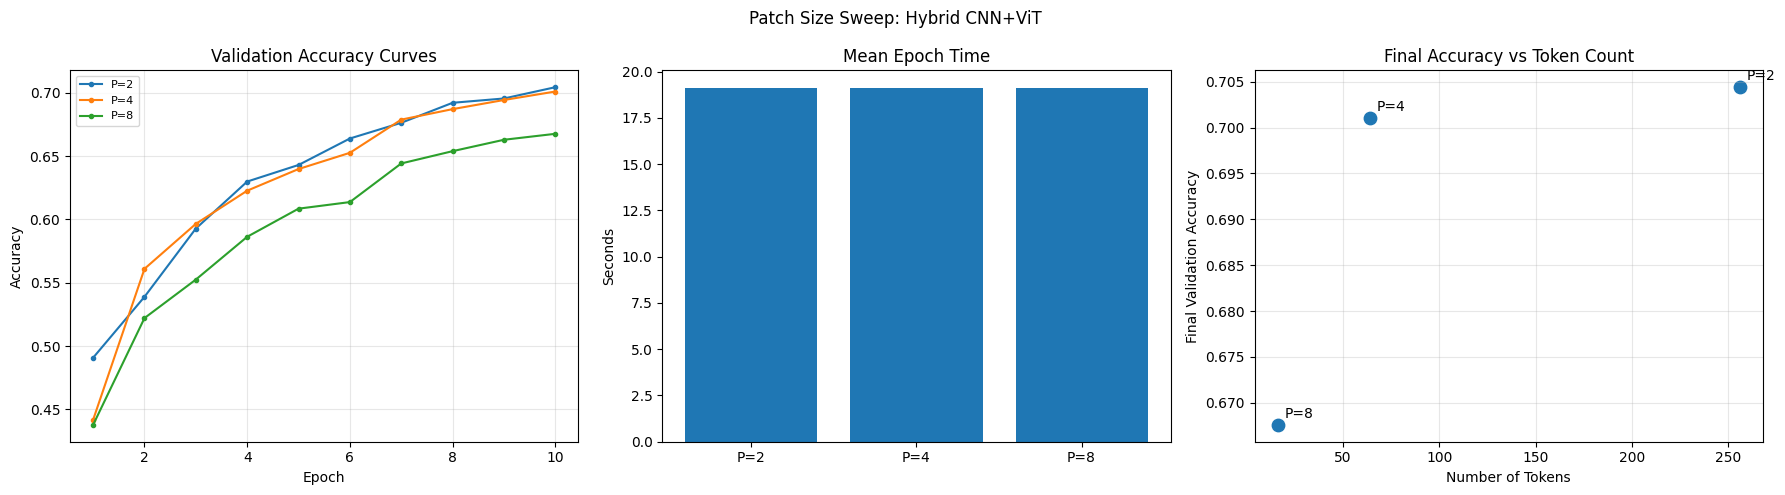

Patch Size     Tokens       Params  Final Val Acc  Mean Epoch Time
2                 256      597,130         0.7044            19.10
Per-class accuracy: [0.757 0.784 0.562 0.467 0.616 0.673 0.812 0.728 0.84  0.805]
4                  64      670,858         0.7010            19.09
Per-class accuracy: [0.755 0.777 0.567 0.456 0.615 0.653 0.823 0.703 0.842 0.819]
8                  16    1,057,930         0.6676            19.11
Per-class accuracy: [0.685 0.794 0.511 0.452 0.574 0.618 0.789 0.682 0.792 0.779]


In [30]:
#TODO: plot training curves for different patch sizes, and print final validation accuracies and per-class accuracies at the end of the sweep
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax_acc, ax_time, ax_scatter = axes
epochs_sw = range(1, EPOCHS_SWEEP + 1)

for P, res in patch_sweep_results.items():
    ax_acc.plot(epochs_sw, res['val_acc'], marker='o', markersize=3, label=f'P={P}')

mean_times = [np.mean(res['epoch_time']) for _, res in patch_sweep_results.items()]
patch_labels = [f'P={P}' for P in patch_sweep_results.keys()]
ax_time.bar(patch_labels, mean_times)

tokens = [res['n_tokens'] for _, res in patch_sweep_results.items()]
final_accs = [res['val_acc'][-1] for _, res in patch_sweep_results.items()]
ax_scatter.scatter(tokens, final_accs, s=80)
for P, x, y in zip(patch_sweep_results.keys(), tokens, final_accs):
    ax_scatter.annotate(f'P={P}', (x, y), textcoords='offset points', xytext=(5, 5))

ax_acc.set_title('Validation Accuracy Curves')
ax_acc.set_xlabel('Epoch')
ax_acc.set_ylabel('Accuracy')
ax_acc.legend(fontsize=8)
ax_acc.grid(True, alpha=0.3)

ax_time.set_title('Mean Epoch Time')
ax_time.set_ylabel('Seconds')

ax_scatter.set_title('Final Accuracy vs Token Count')
ax_scatter.set_xlabel('Number of Tokens')
ax_scatter.set_ylabel('Final Validation Accuracy')
ax_scatter.grid(True, alpha=0.3)

plt.suptitle('Patch Size Sweep: Hybrid CNN+ViT', fontsize=12)
plt.tight_layout()
plt.show()

print(f"{'Patch Size':<12} {'Tokens':>8} {'Params':>12} {'Final Val Acc':>14} {'Mean Epoch Time':>16}")
for P, res in patch_sweep_results.items():
    print(f"{P:<12} {res['n_tokens']:>8} {res['n_params']:>12,} {res['val_acc'][-1]:>14.4f} {np.mean(res['epoch_time']):>16.2f}")
    print('Per-class accuracy:', np.round(res['per_class'], 4))

**[6.3] Analysis — Patch Size Sweep**

*Write your analysis here. Address:*
- *How does validation accuracy scale with P? Is the relationship monotonic?*
- *Quantify the compute cost (epoch time) for each P. At what point do diminishing returns set in?*
- *For a deployment scenario with a hard latency budget, which P would you recommend?*

Answer: validation accuracy decreases as patch size P increases, so the relationship is monotonic in this experiment. The final validation accuracies are 0.7044 for P = 2, 0.7010 for P = 4, and 0.6676 for P = 8. This means smaller patches help the model because they preserve finer spatial detail and give the Transformer access to more localized information. The drop from P =2 to P = 4 is very small, but the drop from P = 4 to P = 8 is much larger, so very coarse patches clearly hurt representation qualty.

The measured compute cost is almost identcal across the three settings.the mean epoch times are about 19.10 seconds for P = 2, 19.09 seconds for P = 4, and 19.11 seconds for P = 8. So in these runs, increasing patch size did not produce a meaningful training-time speedup.thjis means diminishing returns set in immediately from a practical timing perspective, because larger patches reduce the token count from 256 to 64 to 16, but the observed epoch time barely changes. Since P = 8 loses a large amount of accuracy without saving real time here, it is clearly not worthwhile in this setup.

for a deployment scenario with a hard latency budget, I would recommend P = 4 as the best compromise. It uses only 64 tokens instead of 256 for P = 2, yet its final accuracy is only slightly lower by about 0.34 percentage points. P = 8 is more aggressive in reducing token count, but the accuracy drop is too large to justify it. So P= 4 gives a strong balance between efficiency and predictive performance

Thanks